**Week 13**<br />Monday, Nov. 23

# Hyperparameter Tuning

LX 394/694<br />
Coding for Linguists

Sophie Hao


## Announcements

- HW 3 extended to Wednesday, Nov. 25, at 9AM
- Late submissions accepted until Wednesday, Dec. 2, at 9AM
- Class will be **remote** during Week 15 (Dec. 7 and 9)
- Take-home final exam during exam week
- **Today:** Wrap up text classification
- **Weeks 14 and 15:** Statistics of natural language text, Voynich Manuscript


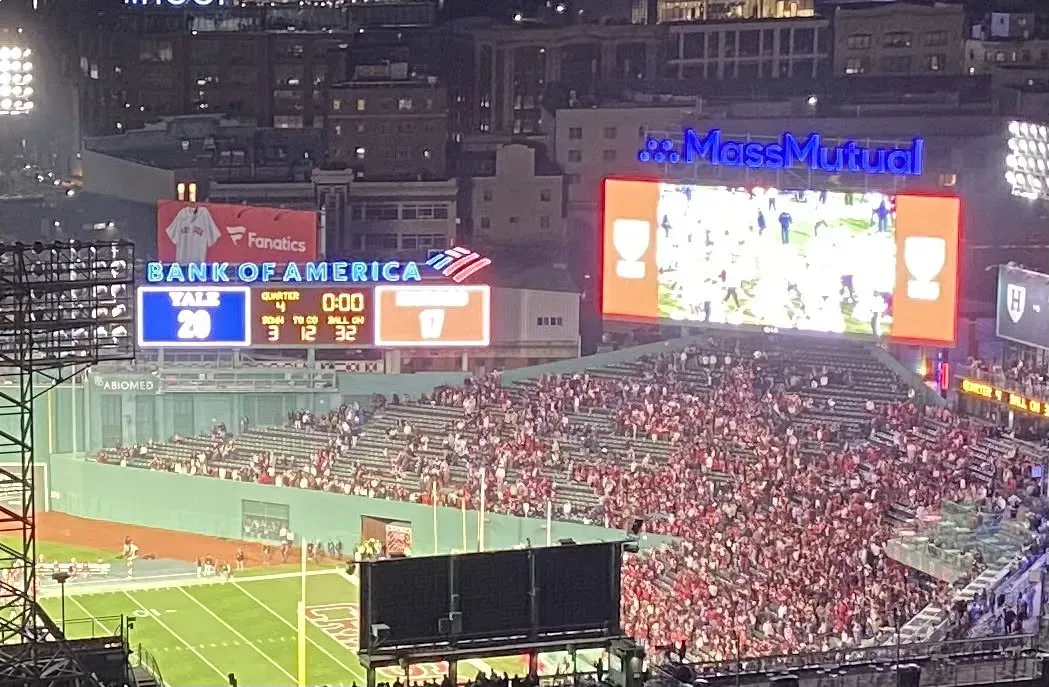

<a style="color: #cccccc" href="https://www.nytimes.com/athletic/7801232/2026/11/21/yale-harvard-football-score-fenway-park/">Go Bulldogs!</a>

## Recap: Text Classification

- Spam filtering _(spam or ham?)_
- Sentiment analysis _(positive or negative?)_
- Hate speech detection _(harmful or safe?)_
- Language identification _(English, Swahili, or Quechua?)_
- Topic modeling _(business, politics, sports, or arts?)_
- Natural language inference _(entailment, contradiction, or neutral?)_
- Technically, language modeling _(a **ton** of possible labels)_

## Recap: Bayesian Classification

Let $C$ be a set of **labels** ("classes"). For a text $x$, a Bayesian classifier generates a **predicted label** $\hat{y} \in C$ as follows:

$$\hat{y} = \underset{c \in C}{\text{argmax}} \log_2(\mathbb{P}[x \mathrel{|} c]) + \log_2(\mathbb{P}[c])$$

where
- $\log_2(\mathbb{P}[x \mathrel{|} c])$ is estimated using a language model 
- $\log_2(\mathbb{P}[c])$ is the proportion of the training corpus with label $c$

## Recap: Binary Unigram Features

Last week, we trained a naïve Bayes sentiment classifier that uses **2,000 binary unigram features**.

Each movie review had a representation that looked something like this:
```python
{'contains(,)': True,
 'contains(the)': True,
 'contains(.)': True,
 'contains(")': False,
 'contains(but)': False,
 'contains(on)': False,
 ...}
```

## Feature Representations

No one says features have to be represented this way!

Other possibilities for feature representations include:
- bigram/trigram features
- word-level sentiment scores
- non-binary features
- different numbers of features (500? 2,000? 5,000?)
- combinations of the above

## Exercise

How do we determine which is the best method for constructing features?

**Solution:** We use **hyperparameter tuning**—we try each method and see which one does best!
- Split data into training, **development**, and testing sets
- For each feature extraction method, train a model using the training set
- Evaluate each of those models on the development set
- Pick the best model, and evaluate that model on the testing set

## Recap: Movie Review Dataset

In [1]:
from nltk.corpus import movie_reviews

# Assign gold labels to each movie review
pos_reviews = [(list(movie_reviews.words(f)), "pos") for f in movie_reviews.fileids("pos")]
neg_reviews = [(list(movie_reviews.words(f)), "neg") for f in movie_reviews.fileids("neg")]

# Combine the reviews
reviews = pos_reviews + neg_reviews

In [2]:
# NLTK helper functions for sentiment analysis
import nltk.sentiment.util as sentiment

train, test = sentiment.split_train_test(reviews)
train, dev = sentiment.split_train_test(train)
train = train[::3]

print(f"{len(train)} train reviews")
print(f"{len(dev)} dev reviews")
print(f"{len(test)} test reviews")

427 train reviews
320 dev reviews
400 test reviews


## Model with Unigram Features

In [3]:
import nltk
from nltk.sentiment import SentimentAnalyzer

unigram_model = SentimentAnalyzer()

# Create unigram features
train_words = unigram_model.all_words(train)
unigrams = unigram_model.unigram_word_feats(train_words, top_n=1000)
unigram_model.add_feat_extractor(sentiment.extract_unigram_feats, unigrams=unigrams)

# Train a classifier
unigram_classifier = unigram_model.train(
    nltk.NaiveBayesClassifier.train, 
    unigram_model.apply_features(train))

Training classifier


## Model with Bigram Features

In [4]:
bigram_model = SentimentAnalyzer()

# Create bigram features
train_docs, _ = zip(*train)
bigrams = bigram_model.bigram_collocation_feats(train_docs, top_n=1000)
bigram_model.add_feat_extractor(sentiment.extract_bigram_feats, bigrams=bigrams)

# Train a classifier
bigram_classifier = bigram_model.train(
    nltk.NaiveBayesClassifier.train, 
    bigram_model.apply_features(train))

Training classifier


## Model with Unigram and Bigram Features

In [5]:
combined_model = SentimentAnalyzer()

# Add unigram and bigram features
combined_model.add_feat_extractor(sentiment.extract_unigram_feats, unigrams=unigrams)
combined_model.add_feat_extractor(sentiment.extract_bigram_feats, bigrams=bigrams)

# Train a classifier
combined_classifier = combined_model.train(
    nltk.NaiveBayesClassifier.train, 
    combined_model.apply_features(train))

Training classifier


## Qualitative Evaluation

In [6]:
unigram_classifier.show_most_informative_features(5)

Most Informative Features
     contains(hilarious) = True              pos : neg    =      9.6 : 1.0
             contains(8) = True              pos : neg    =      8.3 : 1.0
     contains(wonderful) = True              pos : neg    =      6.0 : 1.0
         contains(waste) = True              neg : pos    =      6.0 : 1.0
       contains(message) = True              pos : neg    =      5.3 : 1.0


In [7]:
bigram_classifier.show_most_informative_features(5)

Most Informative Features
         contains(8 - /) = True              pos : neg    =      6.7 : 1.0
contains(worth - seeing) = True              pos : neg    =      6.7 : 1.0
        contains(/ - 10) = True              pos : neg    =      5.3 : 1.0
contains(pulp - fiction) = True              pos : neg    =      5.3 : 1.0
contains(far - superior) = True              neg : pos    =      4.7 : 1.0


In [8]:
combined_classifier.show_most_informative_features(5)

Most Informative Features
     contains(hilarious) = True              pos : neg    =      9.6 : 1.0
             contains(8) = True              pos : neg    =      8.3 : 1.0
         contains(8 - /) = True              pos : neg    =      6.7 : 1.0
contains(worth - seeing) = True              pos : neg    =      6.7 : 1.0
     contains(wonderful) = True              pos : neg    =      6.0 : 1.0


## Tune Hyperparameters

In [9]:
unigram_model.evaluate(unigram_model.apply_features(dev))

Evaluating NaiveBayesClassifier results...


{'Accuracy': 0.715625,
 'Precision [pos]': 0.7019867549668874,
 'Recall [pos]': 0.6973684210526315,
 'F-measure [pos]': 0.6996699669966996,
 'Precision [neg]': 0.727810650887574,
 'Recall [neg]': 0.7321428571428571,
 'F-measure [neg]': 0.7299703264094956}

In [10]:
bigram_model.evaluate(bigram_model.apply_features(dev))

Evaluating NaiveBayesClassifier results...


{'Accuracy': 0.634375,
 'Precision [pos]': 0.6356589147286822,
 'Recall [pos]': 0.5394736842105263,
 'F-measure [pos]': 0.5836298932384342,
 'Precision [neg]': 0.6335078534031413,
 'Recall [neg]': 0.7202380952380952,
 'F-measure [neg]': 0.6740947075208913}

In [11]:
combined_model.evaluate(combined_model.apply_features(dev))

Evaluating NaiveBayesClassifier results...


{'Accuracy': 0.709375,
 'Precision [pos]': 0.7034482758620689,
 'Recall [pos]': 0.6710526315789473,
 'F-measure [pos]': 0.6868686868686867,
 'Precision [neg]': 0.7142857142857143,
 'Recall [neg]': 0.7440476190476191,
 'F-measure [neg]': 0.728862973760933}

## Evaluate on Test Set

In [12]:
unigram_model.evaluate(unigram_model.apply_features(test))

Evaluating NaiveBayesClassifier results...


{'Accuracy': 0.7425,
 'Precision [pos]': 0.7832512315270936,
 'Recall [pos]': 0.7293577981651376,
 'F-measure [pos]': 0.7553444180522565,
 'Precision [neg]': 0.700507614213198,
 'Recall [neg]': 0.7582417582417582,
 'F-measure [neg]': 0.7282321899736147}

## Next Time

Statistics of Language